# `tl.ligrec` vs `squidpy.gr.ligrec`

Astrolabe's CPU `ligrec` restricts every score to actual spatial-graph edges
(sender A, receiver B connected in the graph); squidpy's `ligrec` is a
CellPhoneDB-style test over **all** cells of each type, with no spatial
restriction. To compare the same statistic rather than two different ones,
astrolabe is run here on a **complete graph**: every cell of type A is
paired with every cell of type B, so astrolabe's per-edge mean reduces to
the same cluster-level quantities squidpy computes directly.

`tl.ligrec` now uses the CellPhoneDB averaging convention,
`(mean(L) + mean(R)) / 2`, matching squidpy's own formula (it previously
scored each edge as a product, `L_i * R_j`). On the complete graph this
makes `sender != receiver` an exact algebraic match; `A == B` is still
reported separately, since astrolabe's edge set excludes self-pairs
(`i != j`), which squidpy's cluster-mean formula does not.


In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
import squidpy as sq

mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]

# Fairness step: copy astrolabe's own spatial graph into the obsp key
# squidpy expects, so both tools permute/aggregate over the *identical*
# graph topology rather than two independently-built ones.
adata.obsp["spatial_connectivities"] = adata.obsp["spatial_neighbors_connectivities"].copy()
adata


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\squidpy\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\squidpy\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


...

INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 328 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 4 clusters


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 5670 edges (mean degree 17.3) [generic]


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm', 'leiden'

## Dataset and a shared graph

`ab.datasets.xenium_tiny()`, QC'd, normalized, clustered (Leiden), with
astrolabe's own spatial graph copied into `obsp['spatial_connectivities']` -
the key `squidpy.gr.*` looks for by default. Without this step the two tools
would each build their own KNN graph independently and any disagreement
could just be graph-construction noise, not a real difference in the
statistic itself.


## A complete graph, for a fair comparison

Astrolabe's real spatial graph only connects nearby cells; squidpy's formula
has no such restriction. Writing an all-pairs (minus self-loops)
connectivity matrix into a separate `neighbors_key='complete'` slot lets
astrolabe answer the same spatially-unrestricted question squidpy always
asks, rather than comparing a local statistic to a global one.


In [2]:
import scipy.sparse as sp

n = adata.n_obs
complete_adj = sp.csr_matrix(np.ones((n, n)) - np.eye(n))
adata.obsp["complete_connectivities"] = complete_adj
adata.uns["complete"] = {"connectivities_key": "complete_connectivities", "distances_key": "complete_distances"}


## Astrolabe: `tl.ligrec` on the complete graph

A small curated ligand-receptor gene list, intersected against the panel's
actual `var_names` at runtime (Xenium panels vary by dataset).


In [3]:
import pandas as pd

candidate_pairs = pd.DataFrame({
    "ligand":   ["CCL19", "EDN1",  "CD86", "CD86"],
    "receptor": ["CCR7",  "EDNRB", "CD28", "CTLA4"],
})
lr_pairs = candidate_pairs[
    candidate_pairs["ligand"].isin(adata.var_names) & candidate_pairs["receptor"].isin(adata.var_names)
].reset_index(drop=True)
print(f"{len(lr_pairs)} / {len(candidate_pairs)} candidate LR pairs present in this panel")
lr_pairs


4 / 4 candidate LR pairs present in this panel


,ligand,receptor
0,CCL19,CCR7
1,EDN1,EDNRB
2,CD86,CD28
3,CD86,CTLA4


In [4]:
_t0 = time.perf_counter()
ab.tl.ligrec(mdata, "leiden", lr_pairs, neighbors_key="complete", n_perms=200, seed=0)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
means_astro = adata.uns["ligrec"]["means"]
pvalues_astro = adata.uns["ligrec"]["pvalues"]
means_astro.head()


INFO:astrolabe.tl._neighborhood:ligrec: 4 LR pairs × 16 cell-type pairs; 20 significant at p < 0.05.


astrolabe runtime: 1.3362s


sender                  0                                       1            \
receiver                0         1         2         3         0         1   
ligand receptor                                                               
CCL19  CCR7      0.146416  0.032869  0.031013  0.088299  0.150452  0.036906   
EDN1   EDNRB     0.025028  0.018795  0.073636  0.012774  0.032021  0.025788   
CD86   CD28      0.086988  0.013418  0.000000  0.007546  0.140567  0.066997   
       CTLA4     0.220608  0.019683  0.012931  0.021498  0.274187  0.073262   

sender                                      2                                \
receiver                2         3         0         1         2         3   
ligand receptor                                                               
CCL19  CCR7      0.035049  0.092335  0.162952  0.049406  0.047549  0.104835   
EDN1   EDNRB     0.080629  0.019768  0.045808  0.039576  0.094417  0.033555   
CD86   CD28      0.053579  0.061125  0.093968  0.020397  0.006979  0.014525   
       CTLA4     0.066510  0.075077  0.227587  0.026662  0.019911  0.028478   

sender                  3                                
receiver                0         1         2         3  
ligand receptor                                          
CCL19  CCR7      0.144214  0.030668  0.028811  0.086097  
EDN1   EDNRB     0.036333  0.030100  0.084941  0.024079  
CD86   CD28      0.096598  0.023027  0.009610  0.017156  
       CTLA4     0.230218  0.029293  0.022541  0.031108

## Reference: `squidpy.gr.ligrec`

squidpy expects `interactions=` with `'source'`/`'target'` columns (the same
rename astrolabe's own GPU path already performs when delegating to
`rsc.gr.ligrec`).


In [5]:
interactions = lr_pairs.rename(columns={"ligand": "source", "receptor": "target"})
_t0 = time.perf_counter()
result_sq = sq.gr.ligrec(
    adata, cluster_key="leiden", interactions=interactions,
    n_perms=200, seed=0, threshold=0.05, copy=True, show_progress_bar=False,
    use_raw=False,
)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")
means_ref = result_sq["means"]
pvalues_ref = result_sq["pvalues"]
means_ref.head()


reference runtime: 0.5854s


0                                       1            \
                      0         1         2         3         0         1   
source target                                                               
CCL19  CCR7    0.146416  0.032869  0.031013  0.088299  0.150452  0.036906   
EDN1   EDNRB          0         0         0         0  0.032021  0.025788   
CD86   CD28           0         0         0         0  0.140567  0.066997   
       CTLA4          0         0         0         0  0.274187  0.073262   

                                          2                                \
                      2         3         0         1         2         3   
source target                                                               
CCL19  CCR7    0.035049  0.092335  0.162952  0.049406  0.047549  0.104835   
EDN1   EDNRB   0.080629  0.019768  0.045808  0.039576  0.094417  0.033555   
CD86   CD28           0  0.061125  0.093968  0.020397         0  0.014525   
       CTLA4    0.06651  0.075077  0.227587  0.026662  0.019911  0.028478   

                      3                                
                      0         1         2         3  
source target                                          
CCL19  CCR7    0.144214  0.030668  0.028811  0.086097  
EDN1   EDNRB   0.036333    0.0301  0.084941  0.024079  
CD86   CD28    0.096598  0.023027         0  0.017156  
       CTLA4   0.230218  0.029293  0.022541  0.031108

## Agreement

Restricted to `sender != receiver` pairs, per the algebraic argument above -
`sender == receiver` is expected to diverge for the documented self-pair
reason, and is reported separately rather than folded into the headline
number.


sender != receiver: Pearson r = 0.977953, max |diff| = 7.36e-02  (n=48)
sender == receiver: Pearson r = 0.3383  (n=16, reported separately, see note above)
Runtime: astrolabe 1.3362s vs squidpy 0.5854s (2.3x astrolabe slower) -- astrolabe's call here runs on the injected complete graph (n*(n-1) edges), a much bigger edge set than its real spatial graph would have, so this isn't astrolabe's typical speed.


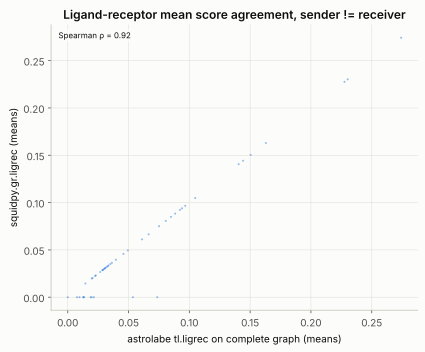

In [6]:
rows = []
for (ligand, receptor) in means_astro.index:
    for (sender, receiver) in means_astro.columns:
        if (ligand, receptor) not in means_ref.index or (sender, receiver) not in means_ref.columns:
            continue
        rows.append({
            "ligand": ligand, "receptor": receptor, "sender": sender, "receiver": receiver,
            "mean_astro": means_astro.loc[(ligand, receptor), (sender, receiver)],
            "mean_ref": means_ref.loc[(ligand, receptor), (sender, receiver)],
            "same_type": sender == receiver,
        })
merged = pd.DataFrame(rows).dropna(subset=["mean_astro", "mean_ref"])

cross = merged[~merged["same_type"]]
same = merged[merged["same_type"]]

r_cross = np.corrcoef(cross["mean_astro"], cross["mean_ref"])[0, 1]
max_diff_cross = float((cross["mean_astro"] - cross["mean_ref"]).abs().max())
print(f"sender != receiver: Pearson r = {r_cross:.6f}, max |diff| = {max_diff_cross:.2e}  (n={len(cross)})")

if len(same) > 0:
    r_same = np.corrcoef(same["mean_astro"], same["mean_ref"])[0, 1]
    print(f"sender == receiver: Pearson r = {r_same:.4f}  (n={len(same)}, reported separately, see note above)")

print(f"Runtime: astrolabe {t_astro_s:.4f}s vs squidpy {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'}) -- "
      f"astrolabe's call here runs on the injected complete graph (n*(n-1) edges), a much bigger "
      f"edge set than its real spatial graph would have, so this isn't astrolabe's typical speed.")

panel = ab.pl.scatter(
    adata, x=cross["mean_astro"].to_numpy(), y=cross["mean_ref"].to_numpy(), annotate_corr=True,
    xlabel="astrolabe tl.ligrec on complete graph (means)", ylabel="squidpy.gr.ligrec (means)",
    title="Ligand-receptor mean score agreement, sender != receiver",
)
panel.show()


## Interpretation

`sender != receiver` should be a strong, near-exact match: astrolabe's
`(mean(L) + mean(R)) / 2` score, computed over every edge of the complete
graph, reduces algebraically to the same per-cluster means squidpy's own
CellPhoneDB formula uses. A small residual gap can remain from details like
raw-vs-normalized input or small-cluster handling. `sender == receiver` is
reported separately and is expected to diverge more, since astrolabe's
edge-based formula never pairs a cell with itself, while squidpy's
cluster-mean formula has no such exclusion.
